In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import snowflake.connector

In [17]:
from dotenv import load_dotenv
import os

load_dotenv("../.env")

print(os.getenv("SNOWFLAKE_ACCOUNT"))
print(os.getenv("SNOWFLAKE_USER"))

ZHWTHYB-ZP41549
daniel.vera.zambrano54@gmail.com


In [18]:
import os
import snowflake.connector
from dotenv import load_dotenv

load_dotenv("../.env")

conn = snowflake.connector.connect(
    account=os.getenv("SNOWFLAKE_ACCOUNT"),
    user=os.getenv("SNOWFLAKE_USER"),
    password=os.getenv("SNOWFLAKE_PASSWORD"),
    warehouse="SNOWFLAKE_LEARNING_WH",
    database="HOME_CREDIT",
    schema="RAW"
)

print("Connected to Snowflake!")

Connected to Snowflake!


In [ ]:
#Preview of data

query = """
SELECT
    TARGET,
    AMT_INCOME_TOTAL,
    AMT_CREDIT,
    AMT_ANNUITY
FROM HOME_CREDIT.RAW.APPLICATION_TRAIN
"""

df = pd.read_sql(query, conn)

df.head()

/var/folders/d9/c1bcvf_16qlbjh5tmkp9zz4r0000gn/T/ipykernel_67485/2765599513.py:12: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


KeyError: 'APPLICATIONS'

/var/folders/d9/c1bcvf_16qlbjh5tmkp9zz4r0000gn/T/ipykernel_67485/3338338031.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


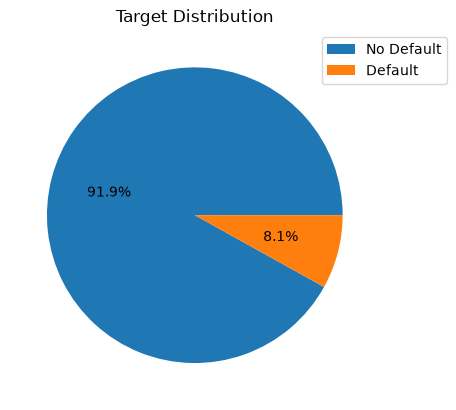

In [31]:
query = """
SELECT
    TARGET,
    COUNT(*) AS APPLICATIONS
FROM HOME_CREDIT.RAW.APPLICATION_TRAIN
GROUP BY TARGET
ORDER BY TARGET
"""

df = pd.read_sql(query, conn)

df

plt.pie(
    df["APPLICATIONS"],
    autopct="%1.1f%%"
)

plt.legend(
    ["No Default", "Default"],
    loc="upper right",
    bbox_to_anchor=(1.2, 1)
)

plt.title("Target Distribution")
plt.show()